# Importing Libraries

In [ ]:

# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES
# TO THE CORRECT LOCATION (/kaggle/input) IN YOUR NOTEBOOK,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

import os
import sys
from tempfile import NamedTemporaryFile
from urllib.request import urlopen
from urllib.parse import unquote, urlparse
from urllib.error import HTTPError
from zipfile import ZipFile
import tarfile
import shutil

CHUNK_SIZE = 40960
DATA_SOURCE_MAPPING = 'lgg-mri-segmentation:https%3A%2F%2Fstorage.googleapis.com%2Fkaggle-data-sets%2F181273%2F407317%2Fbundle%2Farchive.zip%3FX-Goog-Algorithm%3DGOOG4-RSA-SHA256%26X-Goog-Credential%3Dgcp-kaggle-com%2540kaggle-161607.iam.gserviceaccount.com%252F20240428%252Fauto%252Fstorage%252Fgoog4_request%26X-Goog-Date%3D20240428T152518Z%26X-Goog-Expires%3D259200%26X-Goog-SignedHeaders%3Dhost%26X-Goog-Signature%3D9fe93b44fd42fbcac8acd5dcd4733597b68b6775a122eb05c87f0b30d77d5324abed79c016fd20f33bfa1b57356ae9a2274072dc20fc0e5dd31b73f9702fe1decc9289f89bbd6c41f386f365043bcf4b75fcb52bfd9e9c313b5dc0bf82f5d57fcd88c1de139f8490f9a68b31ae1d3929f1e1f9e6977e112b4d929ddda83405f2b15a2fd9cf679d41f4136449518611383e96ddf6b27b393d656fdf2943223938c3b84b64156416714001e49036d419821564f1de1880588304969ff4c6c06948cbdc27423dc8cb357bb558165f164d0f74e0aafa20d6a2ce84cc2b1be8d440517d308383388160a6d7afa81012e3340698ba550e9679247182869c99e7fbe0a6'

KAGGLE_INPUT_PATH='/kaggle/input'
KAGGLE_WORKING_PATH='/kaggle/working'
KAGGLE_SYMLINK='kaggle'

!umount /kaggle/input/ 2> /dev/null
shutil.rmtree('/kaggle/input', ignore_errors=True)
os.makedirs(KAGGLE_INPUT_PATH, 0o777, exist_ok=True)
os.makedirs(KAGGLE_WORKING_PATH, 0o777, exist_ok=True)

try:
  os.symlink(KAGGLE_INPUT_PATH, os.path.join("..", 'input'), target_is_directory=True)
except FileExistsError:
  pass
try:
  os.symlink(KAGGLE_WORKING_PATH, os.path.join("..", 'working'), target_is_directory=True)
except FileExistsError:
  pass

for data_source_mapping in DATA_SOURCE_MAPPING.split(','):
    directory, download_url_encoded = data_source_mapping.split(':')
    download_url = unquote(download_url_encoded)
    filename = urlparse(download_url).path
    destination_path = os.path.join(KAGGLE_INPUT_PATH, directory)
    try:
        with urlopen(download_url) as fileres, NamedTemporaryFile() as tfile:
            total_length = fileres.headers['content-length']
            print(f'Downloading {directory}, {total_length} bytes compressed')
            dl = 0
            data = fileres.read(CHUNK_SIZE)
            while len(data) > 0:
                dl += len(data)
                tfile.write(data)
                done = int(50 * dl / int(total_length))
                sys.stdout.write(f"\r[{'=' * done}{' ' * (50-done)}] {dl} bytes downloaded")
                sys.stdout.flush()
                data = fileres.read(CHUNK_SIZE)
            if filename.endswith('.zip'):
              with ZipFile(tfile) as zfile:
                zfile.extractall(destination_path)
            else:
              with tarfile.open(tfile.name) as tarfile:
                tarfile.extractall(destination_path)
            print(f'\nDownloaded and uncompressed: {directory}')
    except HTTPError as e:
        print(f'Failed to load (likely expired) {download_url} to path {destination_path}')
        continue
    except OSError as e:
        print(f'Failed to load {download_url} to path {destination_path}')
        continue

print('Data source import complete.')

[==================================================] 748584920 bytes downloaded
Downloaded and uncompressed: lgg-mri-segmentation
Data source import complete.


In [ ]:
import pandas as pd
import os
from PIL import Image
import imageio.v2 as imageio
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import cv2

import seaborn as sns
sns.set_style('darkgrid')
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import pathlib

import tensorflow as tf
import tensorflow.keras as keras

from keras.models import Sequential
from keras import Input, Model
from keras import layers

import glob
from tqdm import tqdm

import cv2
import numpy as np
import os
from concurrent.futures import ThreadPoolExecutor, as_completed
import glob
import pathlib
from tqdm import tqdm


In [ ]:
!pip install kaggle

In [ ]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
import os
os.environ['KAGGLE_CONFIG_DIR'] = '/content/drive/MyDrive/kaggle'

# Downloading dataset

In [ ]:
!kaggle datasets download -d mateuszbuda/lgg-mri-segmentation -p /content/drive/MyDrive/BIAI/

lgg-mri-segmentation.zip: Skipping, found more recently modified local copy (use --force to force download)


# Reading images

In [ ]:
#dataset_dir = '/content/drive/MyDrive/BIAI/lgg-mri-segmentation/kaggle_3m/'
dataset_dir = '/kaggle/input/lgg-mri-segmentation/kaggle_3m/'

def process_image(path):
    image = path.replace("_mask", "")
    mask = path

    if os.path.isfile(image):
        mask_pic = cv2.imread(mask, cv2.IMREAD_GRAYSCALE)
        image_pic = cv2.imread(image, cv2.IMREAD_COLOR)
        return (image_pic, mask_pic)
    return None

images = []
masks = []

def getAllImages():
    image_paths = glob.glob(os.path.join(dataset_dir, '**', '*_mask.tif'), recursive=True)
    pbar = tqdm(total=len(image_paths), desc="Processing Images")

    with ThreadPoolExecutor(max_workers=4) as executor:
        # Map the executor to the function and image paths
        # future_to_image = {executor.submit(process_image, path): path for path in image_paths}
        future_to_image = {executor.submit(process_image, path): path for path in image_paths}  # Skipping every alternate image

        # Process as each task completes
        for future in as_completed(future_to_image):
            result = future.result()
            if result:
                images.append(result[0])
                masks.append(result[1])
            # Update the progress bar
            pbar.update(1)

    # Close the progress bar upon completion
    pbar.close()


getAllImages()
# Convert lists to numpy arrays if needed
images_array = np.array(images)
masks_array = np.array(masks)

Processing Images: 100%|██████████| 3929/3929 [00:01<00:00, 3516.81it/s]


In [ ]:
# Display the shapes of the arrays
print('Images array shape:', images_array.shape)
print('Masks array shape:', masks_array.shape)

Images array shape: (3929, 256, 256, 3)
Masks array shape: (3929, 256, 256)


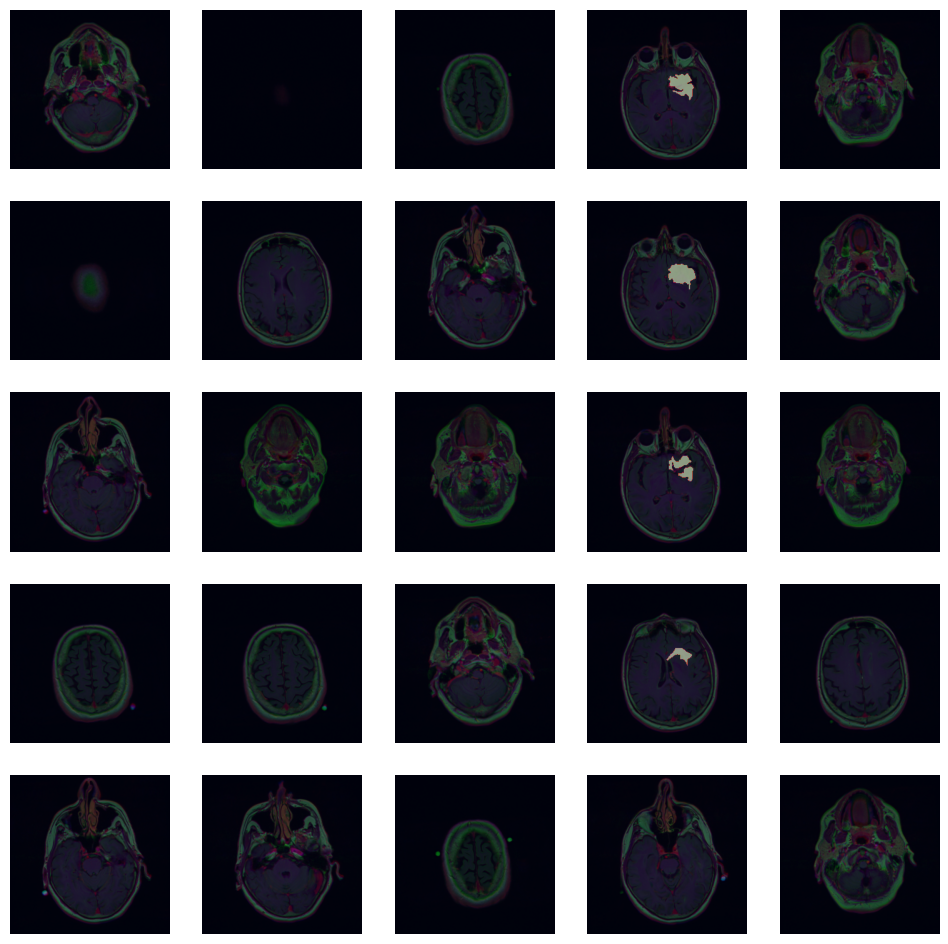

In [ ]:
rows, cols = 5, 5
imageSize = (128, 128)
#imageSize = (64, 64)


fig=plt.figure(figsize=(12, 12))
for i in range(1, rows*cols+1):
    fig.add_subplot(rows, cols, i)
    image= images[i]
    mask = masks[i]
    plt.imshow(image)
    plt.imshow(mask, alpha=0.5)
    plt.grid(False)
    plt.axis('off')
plt.show()

#Data Preprocessing

In [ ]:
##Converting image and mask into dataframe
df = pd.DataFrame(data={'images': images , 'masks': masks})
df.head(5)

,images,masks
0,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
1,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
2,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
3,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
4,"[[[0, 0, 0], [0, 0, 0], [0, 0, 0], [0, 0, 0], ...","[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."


##Resizing image

In [ ]:
X= df['images']
y= df['masks']

# X=np.array(X)

# y=np.array(y)
from skimage import transform
img_size=(128,128)
X = np.array([transform.resize(image, img_size, preserve_range=True) for image in X])
y = np.array([transform.resize(image, img_size, preserve_range=True) for image in y])



##Normalization

In [ ]:
#This additional dimension is necessary because many deep learning frameworks expect the input data to have a consistent number of dimensions,
#and for segmentation tasks, the masks need to be treated as single-channel images.
X_norm=np.array(X) / 255.0
y_norm = np.expand_dims(np.array(y) / 255.0, -1)
#y_norm = np.array(y) / 255.0

## Binarization

In [ ]:
#binarization
for mask in y_norm:
  mask[mask> 0.5] = 1
  mask[mask <= 0.5] = 0

#Train-Test Split

In [ ]:
#Splitting Dataset
X_train, X_test, y_train, y_test = train_test_split(X_norm, y_norm, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)


print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)
print(X_val.shape)
print(y_val.shape)

(2514, 128, 128, 3)
(2514, 128, 128, 1)
(786, 128, 128, 3)
(786, 128, 128, 1)
(629, 128, 128, 3)
(629, 128, 128, 1)


In [ ]:
tumorCount =0
nonTumorCount=0
for mk in y:
  #if max in mask matrix is 1 means it is tumor
  if np.argmax(mk):
    tumorCount+=1
  else:
    nonTumorCount+=1

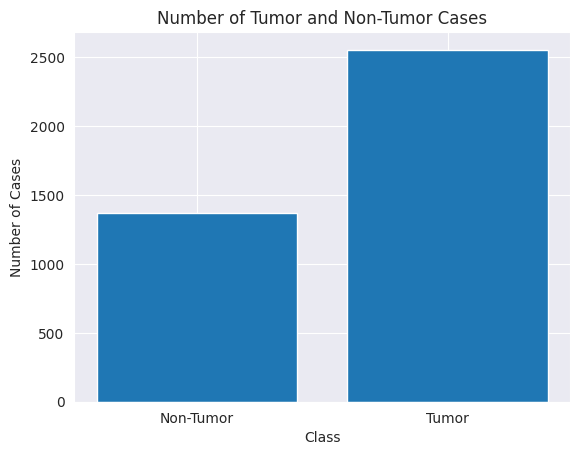

In [ ]:
import matplotlib.pyplot as plt

# Assuming y_train_binary contains the binary labels (0 for non-tumor, 1 for tumor)
# Count the number of occurrences of each class
counts = [tumorCount, nonTumorCount]

# Define labels for the classes
class_labels = ['Non-Tumor', 'Tumor']

# Plotting the bar graph
plt.bar(class_labels, counts)
plt.xlabel('Class')
plt.ylabel('Number of Cases')
plt.title('Number of Tumor and Non-Tumor Cases')
plt.show()


#Model Training

##Attention U-Net

In [ ]:
import keras.backend as K
from keras.losses import binary_crossentropy

import tensorflow as tf

def dice_coefficient(y_true, y_pred):
    epsilon = 1e-6
    y_true_flat = tf.reshape(y_true, [-1])
    y_pred_flat = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_flat * y_pred_flat)
    return (2. * intersection + epsilon) / (tf.reduce_sum(y_true_flat) + tf.reduce_sum(y_pred_flat) + epsilon)

def jaccard_index(y_true, y_pred):
    epsilon = 1e-6
    y_true_flat = tf.reshape(y_true, [-1])
    y_pred_flat = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_flat * y_pred_flat)
    union = tf.reduce_sum(y_true_flat + y_pred_flat - y_true_flat * y_pred_flat)
    return (intersection + epsilon) / (union + epsilon)

def pixel_accuracy(y_true, y_pred):
    correct = tf.equal(tf.round(y_true), tf.round(y_pred))
    return tf.reduce_mean(tf.cast(correct, tf.float32))

def sensitivity(y_true, y_pred):
    epsilon = 1e-6
    true_positives = tf.reduce_sum(tf.round(y_true) * tf.round(y_pred))
    possible_positives = tf.reduce_sum(tf.round(y_true))
    return true_positives / (possible_positives + epsilon)

def specificity(y_true, y_pred):
    epsilon = 1e-6
    true_negatives = tf.reduce_sum((1 - tf.round(y_true)) * (1 - tf.round(y_pred)))
    possible_negatives = tf.reduce_sum(1 - tf.round(y_true))
    return true_negatives / (possible_negatives + epsilon)

In [ ]:
from tensorflow.keras.layers import Input, Activation, BatchNormalization, Dropout,Lambda, Conv2D,MaxPooling2D, concatenate, Dense, Flatten, UpSampling2D

from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation, MaxPool2D, Conv2DTranspose, Concatenate, Input

def conv_block(inp,filters):
    x=Conv2D(filters,(3,3),padding='same',activation='relu')(inp)
    x=Conv2D(filters,(3,3),padding='same')(x)
    x=BatchNormalization(axis=3)(x)
    x=Activation('relu')(x)
    return x

def encoder_block(inp,filters,dropout):
    x=conv_block(inp,filters)
    p=MaxPooling2D(pool_size=(2,2))(x)
    p=Dropout(dropout)(p)
    return x,p

def attention_block(l_layer,h_layer): #Attention Block
    phi=Conv2D(h_layer.shape[-1],(1,1),padding='same')(l_layer)
    theta=Conv2D(h_layer.shape[-1],(1,1),strides=(2,2),padding='same')(h_layer)
    x=tf.keras.layers.add([phi,theta])
    x=Activation('relu')(x)
    x=Conv2D(1,(1,1),padding='same',activation='sigmoid')(x)
    x=UpSampling2D(size=(2,2))(x)
    x=tf.keras.layers.multiply([h_layer,x])
    x=BatchNormalization(axis=3)(x)
    return x

def decoder_block(inp,filters,concat_layer,dropout):
    x=Conv2DTranspose(filters,(2,2),strides=(2,2),padding='same')(inp)
    concat_layer=attention_block(inp,concat_layer)
    x=concatenate([x,concat_layer])
    x=Dropout(dropout)(x)
    x=conv_block(x,filters)
    return x

In [ ]:
input_img = Input((128,128,3), name='img')
d1,p1=encoder_block(input_img,64,0.1)
d2,p2=encoder_block(p1,128,0.1)
d3,p3=encoder_block(p2,256,0.1)
d4,p4=encoder_block(p3,512,0.1)
b1=conv_block(p4,1024)
e2=decoder_block(b1,512,d4,0.1)
e3=decoder_block(e2,256,d3,0.1)
e4=decoder_block(e3,128,d2,0.1)
e5=decoder_block(e4,64,d1,0.1)
outputs = Conv2D(1, (1,1),activation="sigmoid")(e5)
model_1=Model(inputs=[input_img], outputs=[outputs],name='AttentionUnet')

In [ ]:
model_1.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        dice_coefficient,
        jaccard_index,
        pixel_accuracy,
        sensitivity,
        specificity,
        'accuracy'
    ]
)
model_1.summary()

Model: "AttentionUnet"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 img (InputLayer)            [(None, 128, 128, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 128, 128, 64)         1792      ['img[0][0]']                 
                                                                                                  
 conv2d_1 (Conv2D)           (None, 128, 128, 64)         36928     ['conv2d[0][0]']              
                                                                                                  
 batch_normalization (Batch  (None, 128, 128, 64)         256       ['conv2d_1[0][0]']            
 Normalization)                                                                       

## Early Stopping - Pixel Accuracy

In [ ]:
MODEL_CHECKPOINT = f"/kaggle/working/model/{model_1.name}.ckpt"
EPOCHS = 100

callbacks_list = [
    keras.callbacks.EarlyStopping(monitor='val_pixel_accuracy', mode='max', patience=5),
    keras.callbacks.ModelCheckpoint(filepath=MODEL_CHECKPOINT, monitor='val_pixel_accuracy', save_best_only=True, mode='max', verbose=1)
]

history = model_1.fit(
    x=X_train,
    y=y_train,
    epochs=EPOCHS,
    callbacks=callbacks_list,
    validation_split=0.2,
    verbose=1)

Epoch 1/100
52/63 [=======================>......] - ETA: 6s - loss: 0.0453 - dice_coefficient: 0.1841 - jaccard_index: 0.1028 - pixel_accuracy: 0.9919 - sensitivity: 0.4118 - specificity: 0.9982 - accuracy: 0.9919

KeyboardInterrupt: 

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import load_model

import tensorflow as tf

import json

with open('history10.json', 'r') as f:
    history = json.load(f)

# @tf.keras.utils.register_keras_serializable()
# def dice_coefficient(y_true, y_pred, smooth=1e-6):
#     y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
#     y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
#     intersection = tf.reduce_sum(y_true_f * y_pred_f)
#     return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)


model = load_model('unet5.keras', custom_objects={
    'dice_coefficient': dice_coefficient,
    'jaccard_index':jaccard_index,
   ' pixel_accuracy':pixel_accuracy,
     'sensitivity': sensitivity,
       'specificity': specificity

})

BadZipFile: Bad magic number for file header

In [ ]:
y_pred_1 = model.predict(X_test)
y_pred_1 = (y_pred_1 > 0.5).astype(np.float64)

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from tensorflow.keras.metrics import MeanIoU

# cm = confusion_matrix(y_test, y_pred)
pixel_accuracy_1 = accuracy_score(y_test.flatten(), y_pred_1.flatten())
dice_coefficient_1 = 2 * tf.reduce_sum(y_test * y_pred_1) / (tf.reduce_sum(y_test) + tf.reduce_sum(y_pred_1))
intersection = np.logical_and(y_test, y_pred_1)
union = np.logical_or(y_test, y_pred_1)
iou_1 = np.sum(intersection) / np.sum(union)
# Print the confusion matrix
# print("Confusion Matrix:")
# print(cm)
print("Pixel Accuracy:", pixel_accuracy_1)
print("Dice Coefficient:", dice_coefficient_1.numpy())
print("Jaccard Index (IoU):", iou_1)

25/25 [==============================] - 4s 133ms/step
Pixel Accuracy: 0.9980620949626272
Dice Coefficient: 0.9024897238328932
Jaccard Index (IoU): 0.8223063997037965


In [ ]:
def calculate_metrics(history):

  dice_scores = history['dice_coefficient']
  jaccard_scores = history['jaccard_index']
  pixel_accuracies = history['pixel_accuracy']
  sensitivity_scores = history['sensitivity']
  specificity_scores = history['specificity']
  accuracy_scores = history['accuracy']

  print("Final Dice Coefficient:", dice_scores[-1])
  print("Final Jaccard Index:", jaccard_scores[-1])
  print("Final Pixel Accuracy:", pixel_accuracies[-1])
  print("Final Sensitivity:", sensitivity_scores[-1])
  print("Final Specificity:", specificity_scores[-1])
  print("Final Accuracy:", accuracy_scores[-1])

  #calculate the average or maximum if needed
  print("Average Dice Coefficient:", sum(dice_scores) / len(dice_scores))

In [ ]:
calculate_metrics(history)

Final Dice Coefficient: 0.9121312499046326
Final Jaccard Index: 0.8388082981109619
Final Pixel Accuracy: 0.9987448453903198
Final Sensitivity: 0.9403690099716187
Final Specificity: 0.9993833303451538
Final Accuracy: 0.9987431168556213
Average Dice Coefficient: 0.7591938403248787


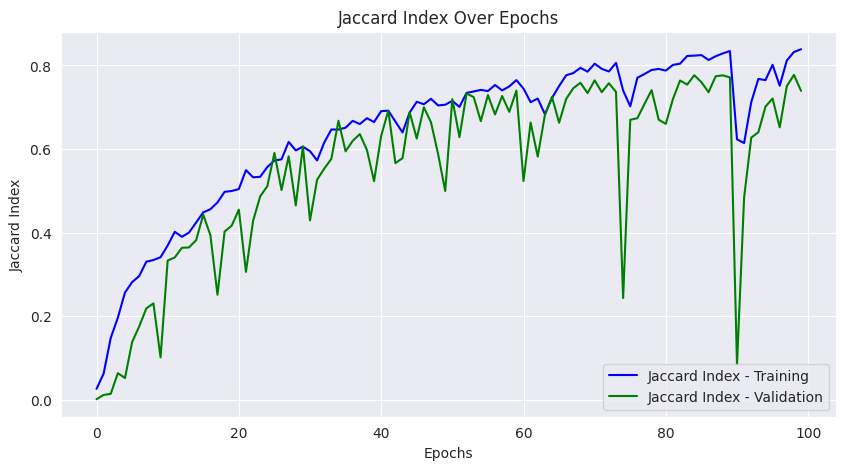

In [ ]:
#plot IoU metric, Jaccard index
jaccard_train = history['jaccard_index']
jaccard_val = history['val_jaccard_index']

plt.figure(figsize=(10, 5))
plt.plot(jaccard_train, label='Jaccard Index - Training', color='blue')
plt.plot(jaccard_val, label='Jaccard Index - Validation', color='green')

# Adding titles and labels
plt.title('Jaccard Index Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Jaccard Index')
plt.legend(loc='lower right')

# Show the plot
plt.show()

## Early Stopping - Loss

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

MODEL_CHECKPOINT = f"/kaggle/working/model/{model_1.name}.ckpt"
EPOCHS = 20


# callbacks_list = [
#     keras.callbacks.EarlyStopping(monitor='val_loss', mode='max', patience=5),
#     keras.callbacks.ModelCheckpoint(filepath=MODEL_CHECKPOINT, monitor='val_pixel_accuracy', save_best_only=True, mode='max', verbose=1)
# ]


early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint(filepath=MODEL_CHECKPOINT, monitor='val_loss', save_best_only=True, mode='min', verbose=1)
callbacks_list = [early_stopping, checkpoint_callback]

history = model_1.fit(
    x=X_train,
    y=y_train,
    epochs=EPOCHS,
    callbacks=callbacks_list,
    validation_split=0.2,
    verbose=1)

Epoch 1/20
40/40 [==============================] - ETA: 0s - loss: 0.0177 - dice_coefficient: 0.5098 - jaccard_index: 0.3490 - pixel_accuracy: 0.9951 - sensitivity: 0.6743 - specificity: 0.9983 - accuracy: 0.9951
Epoch 1: val_loss improved from inf to 0.02450, saving model to /kaggle/working/model/AttentionUnet.ckpt
40/40 [==============================] - 25s 635ms/step - loss: 0.0177 - dice_coefficient: 0.5098 - jaccard_index: 0.3490 - pixel_accuracy: 0.9951 - sensitivity: 0.6743 - specificity: 0.9983 - accuracy: 0.9951 - val_loss: 0.0245 - val_dice_coefficient: 0.3953 - val_jaccard_index: 0.2489 - val_pixel_accuracy: 0.9934 - val_sensitivity: 0.4805 - val_specificity: 0.9990 - val_accuracy: 0.9934
Epoch 2/20
40/40 [==============================] - ETA: 0s - loss: 0.0183 - dice_coefficient: 0.5099 - jaccard_index: 0.3454 - pixel_accuracy: 0.9948 - sensitivity: 0.6483 - specificity: 0.9984 - accuracy: 0.9947
Epoch 2: val_loss improved from 0.02450 to 0.02073, saving model to /kaggle

In [ ]:
y_pred_2 = model_1.predict(X_test)
y_pred_2 = (y_pred_2 > 0.5).astype(np.float64)

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from tensorflow.keras.metrics import MeanIoU

# cm = confusion_matrix(y_test, y_pred)
pixel_accuracy_1 = accuracy_score(y_test.flatten(), y_pred_2.flatten())
dice_coefficient_1 = 2 * tf.reduce_sum(y_test * y_pred_2) / (tf.reduce_sum(y_test) + tf.reduce_sum(y_pred_2))
intersection = np.logical_and(y_test, y_pred_2)
union = np.logical_or(y_test, y_pred_2)
iou_1 = np.sum(intersection) / np.sum(union)
# Print the confusion matrix
# print("Confusion Matrix:")
# print(cm)
print("Pixel Accuracy:", pixel_accuracy_1)
print("Dice Coefficient:", dice_coefficient_1.numpy())
print("Jaccard Index (IoU):", iou_1)

13/13 [==============================] - 1s 46ms/step
Pixel Accuracy: 0.9963409967398219
Dice Coefficient: 0.7933623351108616
Jaccard Index (IoU): 0.6574984008838751


## Early Stopping - Dice Coefficient

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import json


MODEL_CHECKPOINT = f"/kaggle/working/model/{model_1.name}.ckpt"
EPOCHS = 100

callbacks_list = [
    keras.callbacks.EarlyStopping(monitor='val_dsc', mode='max', patience=10),
    keras.callbacks.ModelCheckpoint(filepath=MODEL_CHECKPOINT, monitor='val_dsc', save_best_only=True, mode='max', verbose=0)
]

import json

history = model_1.fit(
    x=X_train,
    y=y_train,
    epochs=EPOCHS,
    callbacks=callbacks_list,
    validation_split=0.2,
    verbose=1)

y_pred_2 = model_1.predict(X_test)
y_pred_2 = (y_pred_2 > 0.5).astype(np.float64)

import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix, accuracy_score

y_pred_2 = model.predict(X_test)
y_pred_2 = (y_pred_2 > 0.5).astype(np.float64)

# Computing the confusion matrix
cm = confusion_matrix(y_test.flatten(), y_pred_2.flatten())

TP = cm[1, 1]
FN = cm[1, 0]
TN = cm[0, 0]
FP = cm[0, 1]

sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)

pixel_accuracy_1 = accuracy_score(y_test.flatten(), y_pred_2.flatten())
dice_coefficient_1 = 2 * tf.reduce_sum(y_test * y_pred_2) / (tf.reduce_sum(y_test) + tf.reduce_sum(y_pred_2))
intersection = np.logical_and(y_test, y_pred_2)
union = np.logical_or(y_test, y_pred_2)
iou_1 = np.sum(intersection) / np.sum(union)

# Output results
print("Confusion Matrix:")
print(cm)
print("Pixel Accuracy:", pixel_accuracy_1)
print("Dice Coefficient:", dice_coefficient_1.numpy())
print("Jaccard Index (IoU):", iou_1)
print("Sensitivity (Recall):", sensitivity)
print("Specificity:", specificity)


import matplotlib.pyplot as plt

# Assuming 'history' contains the training history with loss values
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(train_loss) + 1)

plt.plot(epochs, train_loss, label='Training loss')
plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()




Epoch 1/100
63/63 [==============================] - ETA: 0s - loss: 0.0315 - dice_coefficient: 0.3075 - jaccard_index: 0.1856 - pixel_accuracy: 0.9924 - sensitivity: 0.4890 - specificity: 0.9979 - accuracy: 0.9924

63/63 [==============================] - 52s 642ms/step - loss: 0.0315 - dice_coefficient: 0.3075 - jaccard_index: 0.1856 - pixel_accuracy: 0.9924 - sensitivity: 0.4890 - specificity: 0.9979 - accuracy: 0.9924 - val_loss: 0.0686 - val_dice_coefficient: 0.1557 - val_jaccard_index: 0.0852 - val_pixel_accuracy: 0.9910 - val_sensitivity: 0.5778 - val_specificity: 0.9954 - val_accuracy: 0.9910
Epoch 2/100
63/63 [==============================] - ETA: 0s - loss: 0.0219 - dice_coefficient: 0.4445 - jaccard_index: 0.2897 - pixel_accuracy: 0.9935 - sensitivity: 0.5546 - specificity: 0.9982 - accuracy: 0.9935

63/63 [==============================] - 39s 617ms/step - loss: 0.0219 - dice_coefficient: 0.4445 - jaccard_index: 0.2897 - pixel_accuracy: 0.9935 - sensitivity: 0.5546 - specificity: 0.9982 - accuracy: 0.9935 - val_loss: 0.0579 - val_dice_coefficient: 0.1504 - val_jaccard_index: 0.0819 - val_pixel_accuracy: 0.9920 - val_sensitivity: 0.3780 - val_specificity: 0.9987 - val_accuracy: 0.9920
Epoch 3/100
63/63 [==============================] - ETA: 0s - loss: 0.0199 - dice_coefficient: 0.4972 - jaccard_index: 0.3346 - pixel_accuracy: 0.9937 - sensitivity: 0.6101 - specificity: 0.9980 - accuracy: 0.9937

63/63 [==============================] - 39s 621ms/step - loss: 0.0199 - dice_coefficient: 0.4972 - jaccard_index: 0.3346 - pixel_accuracy: 0.9937 - sensitivity: 0.6101 - specificity: 0.9980 - accuracy: 0.9937 - val_loss: 0.0416 - val_dice_coefficient: 0.2514 - val_jaccard_index: 0.1451 - val_pixel_accuracy: 0.9935 - val_sensitivity: 0.6006 - val_specificity: 0.9977 - val_accuracy: 0.9935
Epoch 4/100
63/63 [==============================] - ETA: 0s - loss: 0.0177 - dice_coefficient: 0.5269 - jaccard_index: 0.3610 - pixel_accuracy: 0.9938 - sensitivity: 0.6373 - specificity: 0.9977 - accuracy: 0.9938

63/63 [==============================] - 39s 622ms/step - loss: 0.0177 - dice_coefficient: 0.5269 - jaccard_index: 0.3610 - pixel_accuracy: 0.9938 - sensitivity: 0.6373 - specificity: 0.9977 - accuracy: 0.9938 - val_loss: 0.0230 - val_dice_coefficient: 0.4731 - val_jaccard_index: 0.3112 - val_pixel_accuracy: 0.9932 - val_sensitivity: 0.3997 - val_specificity: 0.9996 - val_accuracy: 0.9932
Epoch 5/100
63/63 [==============================] - ETA: 0s - loss: 0.0161 - dice_coefficient: 0.5651 - jaccard_index: 0.3974 - pixel_accuracy: 0.9944 - sensitivity: 0.6598 - specificity: 0.9982 - accuracy: 0.9944

...

63/63 [==============================] - 39s 624ms/step - loss: 0.0020 - dice_coefficient: 0.9406 - jaccard_index: 0.8880 - pixel_accuracy: 0.9992 - sensitivity: 0.9592 - specificity: 0.9996 - accuracy: 0.9992 - val_loss: 0.0089 - val_dice_coefficient: 0.8842 - val_jaccard_index: 0.7936 - val_pixel_accuracy: 0.9978 - val_sensitivity: 0.8708 - val_specificity: 0.9992 - val_accuracy: 0.9978
Epoch 98/100
63/63 [==============================] - ETA: 0s - loss: 0.0020 - dice_coefficient: 0.9399 - jaccard_index: 0.8870 - pixel_accuracy: 0.9992 - sensitivity: 0.9586 - specificity: 0.9996 - accuracy: 0.9992

63/63 [==============================] - 39s 623ms/step - loss: 0.0020 - dice_coefficient: 0.9399 - jaccard_index: 0.8870 - pixel_accuracy: 0.9992 - sensitivity: 0.9586 - specificity: 0.9996 - accuracy: 0.9992 - val_loss: 0.0104 - val_dice_coefficient: 0.8701 - val_jaccard_index: 0.7718 - val_pixel_accuracy: 0.9976 - val_sensitivity: 0.8480 - val_specificity: 0.9992 - val_accuracy: 0.9976
Epoch 99/100
63/63 [==============================] - ETA: 0s - loss: 0.0024 - dice_coefficient: 0.9267 - jaccard_index: 0.8638 - pixel_accuracy: 0.9990 - sensitivity: 0.9500 - specificity: 0.9995 - accuracy: 0.9990

63/63 [==============================] - 39s 623ms/step - loss: 0.0024 - dice_coefficient: 0.9267 - jaccard_index: 0.8638 - pixel_accuracy: 0.9990 - sensitivity: 0.9500 - specificity: 0.9995 - accuracy: 0.9990 - val_loss: 0.0084 - val_dice_coefficient: 0.8935 - val_jaccard_index: 0.8082 - val_pixel_accuracy: 0.9980 - val_sensitivity: 0.8904 - val_specificity: 0.9992 - val_accuracy: 0.9980
Epoch 100/100
63/63 [==============================] - ETA: 0s - loss: 0.0026 - dice_coefficient: 0.9206 - jaccard_index: 0.8543 - pixel_accuracy: 0.9989 - sensitivity: 0.9471 - specificity: 0.9994 - accuracy: 0.9989

25/25 [==============================] - 10s 382ms/step


NameError: name 'model' is not defined

In [ ]:
model_1.save("unet9.keras")
with open('history9.json', 'w') as f:
    json.dump(history.history, f)

In [ ]:
y_pred_3 = model_1.predict(X_test)
y_pred_3 = (y_pred_3 > 0.5).astype(np.float64)

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from tensorflow.keras.metrics import MeanIoU

# cm = confusion_matrix(y_test, y_pred)
pixel_accuracy_1 = accuracy_score(y_test.flatten(), y_pred_3.flatten())
dice_coefficient_1 = 2 * tf.reduce_sum(y_test * y_pred_3) / (tf.reduce_sum(y_test) + tf.reduce_sum(y_pred_3))
intersection = np.logical_and(y_test, y_pred_3)
union = np.logical_or(y_test, y_pred_3)
iou_1 = np.sum(intersection) / np.sum(union)
# Print the confusion matrix
# print("Confusion Matrix:")
# print(cm)
print("Pixel Accuracy:", pixel_accuracy_1)
print("Dice Coefficient:", dice_coefficient_1.numpy())
print("Jaccard Index (IoU):", iou_1)

25/25 [==============================] - 10s 378ms/step
Pixel Accuracy: 0.9979859174966206
Dice Coefficient: 0.9067312982534369
Jaccard Index (IoU): 0.8293764349101722


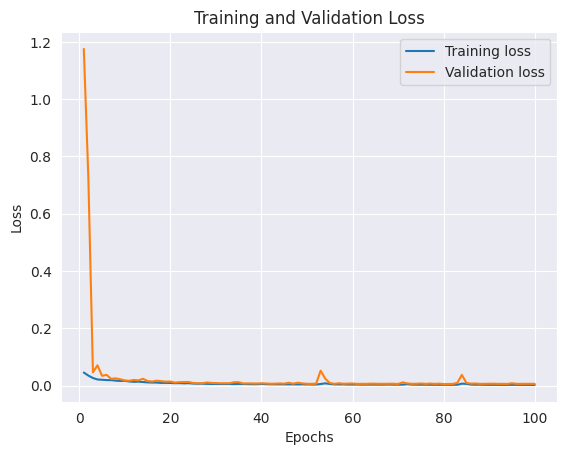

In [ ]:
import matplotlib.pyplot as plt

# Assuming 'history' contains the training history with loss values
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(train_loss) + 1)

plt.plot(epochs, train_loss, label='Training loss')
plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [ ]:
#plot IoU metric, Jaccard index
jaccard_train = history.history['jaccard_index']
jaccard_val = history.history['val_jaccard_index']

plt.figure(figsize=(10, 5))
plt.plot(jaccard_train, label='Jaccard Index - Training', color='blue')
plt.plot(jaccard_val, label='Jaccard Index - Validation', color='green')

# Adding titles and labels
plt.title('Jaccard Index Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Jaccard Index')
plt.legend(loc='lower right')

# Show the plot
plt.show()

## Tuning Loss function

In [ ]:
import tensorflow as tf

def dice_loss(y_true, y_pred):
    smooth = 1e-6  # To avoid division by zero
    # Flatten the labels and predictions
    y_true_flat = tf.reshape(y_true, [-1])
    y_pred_flat = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_flat * y_pred_flat)
    denominator = tf.reduce_sum(y_true_flat) + tf.reduce_sum(y_pred_flat)

    dice = (2. * intersection + smooth) / (denominator + smooth)
    return 1 - dice  # Dice loss


def cross_entropy_loss(y_true, y_pred):
    return tf.keras.losses.binary_crossentropy(y_true, y_pred)

def combined_dice_crossentropy_loss(y_true, y_pred, dice_weight=0.5, ce_weight=0.5):
  dice = dice_loss(y_true, y_pred)
  cross_entropy = cross_entropy_loss(y_true, y_pred)

  # Weighted sum of the two losses
  return dice_weight * dice + ce_weight * cross_entropy


In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from tensorflow.keras.metrics import MeanIoU
def calculate_metrics_sk_learn():
  # cm = confusion_matrix(y_test, y_pred)
  pixel_accuracy = accuracy_score(y_test.flatten(), y_pred.flatten())
  dice_coefficient = 2 * tf.reduce_sum(y_test * y_pred) / (tf.reduce_sum(y_test) + tf.reduce_sum(y_pred))
  intersection = np.logical_and(y_test, y_pred)
  union = np.logical_or(y_test, y_pred)
  iou = np.sum(intersection) / np.sum(union)
  # Print the confusion matrix
  # print("Confusion Matrix:")
  # print(cm)
  print("Pixel Accuracy:", pixel_accuracy)
  print("Dice Coefficient:", dice_coefficient.numpy())
  print("Jaccard Index (IoU):", iou)

## Tuning Batch Size

In [ ]:
from keras.optimizers import Adam

bs = 64

model_1.compile(
    optimizer= 'Adam',
    loss=combined_dice_crossentropy_loss,
    metrics=[
        dice_coefficient,
        jaccard_index,
        pixel_accuracy,
        sensitivity,
        specificity,
        'accuracy'
    ]
)
model_1.summary()

Model: "AttentionUnet"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 img (InputLayer)            [(None, 128, 128, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 128, 128, 64)         1792      ['img[0][0]']                 
                                                                                                  
 conv2d_1 (Conv2D)           (None, 128, 128, 64)         36928     ['conv2d[0][0]']              
                                                                                                  
 batch_normalization (Batch  (None, 128, 128, 64)         256       ['conv2d_1[0][0]']            
 Normalization)                                                                       

Epoch 1/100
32/32 [==============================] - ETA: 0s - loss: 0.5331 - dice_coefficient: 0.1116 - jaccard_index: 0.0601 - pixel_accuracy: 0.9628 - sensitivity: 0.5846 - specificity: 0.9667 - accuracy: 0.9625

32/32 [==============================] - 133s 2s/step - loss: 0.5331 - dice_coefficient: 0.1116 - jaccard_index: 0.0601 - pixel_accuracy: 0.9628 - sensitivity: 0.5846 - specificity: 0.9667 - accuracy: 0.9625 - val_loss: 1.6134 - val_dice_coefficient: 0.0271 - val_jaccard_index: 0.0138 - val_pixel_accuracy: 0.1748 - val_sensitivity: 0.9999 - val_specificity: 0.1656 - val_accuracy: 0.1751
Epoch 2/100
32/32 [==============================] - ETA: 0s - loss: 0.4201 - dice_coefficient: 0.2296 - jaccard_index: 0.1314 - pixel_accuracy: 0.9868 - sensitivity: 0.5973 - specificity: 0.9910 - accuracy: 0.9868

32/32 [==============================] - 39s 1s/step - loss: 0.4201 - dice_coefficient: 0.2296 - jaccard_index: 0.1314 - pixel_accuracy: 0.9868 - sensitivity: 0.5973 - specificity: 0.9910 - accuracy: 0.9868 - val_loss: 0.8589 - val_dice_coefficient: 0.0241 - val_jaccard_index: 0.0122 - val_pixel_accuracy: 0.5645 - val_sensitivity: 0.6250 - val_specificity: 0.5638 - val_accuracy: 0.5646
Epoch 3/100
32/32 [==============================] - ETA: 0s - loss: 0.3314 - dice_coefficient: 0.3861 - jaccard_index: 0.2414 - pixel_accuracy: 0.9911 - sensitivity: 0.5879 - specificity: 0.9953 - accuracy: 0.9910

32/32 [==============================] - 38s 1s/step - loss: 0.3314 - dice_coefficient: 0.3861 - jaccard_index: 0.2414 - pixel_accuracy: 0.9911 - sensitivity: 0.5879 - specificity: 0.9953 - accuracy: 0.9910 - val_loss: 0.6392 - val_dice_coefficient: 0.0246 - val_jaccard_index: 0.0124 - val_pixel_accuracy: 0.9889 - val_sensitivity: 0.0000e+00 - val_specificity: 1.0000 - val_accuracy: 0.9889
Epoch 4/100
32/32 [==============================] - ETA: 0s - loss: 0.2797 - dice_coefficient: 0.4814 - jaccard_index: 0.3200 - pixel_accuracy: 0.9916 - sensitivity: 0.5662 - specificity: 0.9961 - accuracy: 0.9916

32/32 [==============================] - 38s 1s/step - loss: 0.2797 - dice_coefficient: 0.4814 - jaccard_index: 0.3200 - pixel_accuracy: 0.9916 - sensitivity: 0.5662 - specificity: 0.9961 - accuracy: 0.9916 - val_loss: 0.8039 - val_dice_coefficient: 0.0307 - val_jaccard_index: 0.0156 - val_pixel_accuracy: 0.4685 - val_sensitivity: 0.9950 - val_specificity: 0.4626 - val_accuracy: 0.4688
Epoch 5/100
32/32 [==============================] - ETA: 0s - loss: 0.2437 - dice_coefficient: 0.5508 - jaccard_index: 0.3833 - pixel_accuracy: 0.9927 - sensitivity: 0.5677 - specificity: 0.9972 - accuracy: 0.9926

...

32/32 [==============================] - 38s 1s/step - loss: 0.0565 - dice_coefficient: 0.8966 - jaccard_index: 0.8133 - pixel_accuracy: 0.9980 - sensitivity: 0.8977 - specificity: 0.9990 - accuracy: 0.9980 - val_loss: 0.0848 - val_dice_coefficient: 0.8512 - val_jaccard_index: 0.7422 - val_pixel_accuracy: 0.9970 - val_sensitivity: 0.7931 - val_specificity: 0.9993 - val_accuracy: 0.9970
Epoch 97/100
32/32 [==============================] - ETA: 0s - loss: 0.0573 - dice_coefficient: 0.8965 - jaccard_index: 0.8135 - pixel_accuracy: 0.9979 - sensitivity: 0.9027 - specificity: 0.9989 - accuracy: 0.9979

32/32 [==============================] - 38s 1s/step - loss: 0.0573 - dice_coefficient: 0.8965 - jaccard_index: 0.8135 - pixel_accuracy: 0.9979 - sensitivity: 0.9027 - specificity: 0.9989 - accuracy: 0.9979 - val_loss: 0.0796 - val_dice_coefficient: 0.8612 - val_jaccard_index: 0.7570 - val_pixel_accuracy: 0.9971 - val_sensitivity: 0.8479 - val_specificity: 0.9987 - val_accuracy: 0.9971
Epoch 98/100
32/32 [==============================] - ETA: 0s - loss: 0.0581 - dice_coefficient: 0.8949 - jaccard_index: 0.8107 - pixel_accuracy: 0.9980 - sensitivity: 0.8963 - specificity: 0.9990 - accuracy: 0.9980

32/32 [==============================] - 38s 1s/step - loss: 0.0581 - dice_coefficient: 0.8949 - jaccard_index: 0.8107 - pixel_accuracy: 0.9980 - sensitivity: 0.8963 - specificity: 0.9990 - accuracy: 0.9980 - val_loss: 0.0811 - val_dice_coefficient: 0.8587 - val_jaccard_index: 0.7532 - val_pixel_accuracy: 0.9970 - val_sensitivity: 0.8302 - val_specificity: 0.9989 - val_accuracy: 0.9970
Epoch 99/100
32/32 [==============================] - ETA: 0s - loss: 0.0496 - dice_coefficient: 0.9074 - jaccard_index: 0.8317 - pixel_accuracy: 0.9983 - sensitivity: 0.9176 - specificity: 0.9991 - accuracy: 0.9982

32/32 [==============================] - 38s 1s/step - loss: 0.0496 - dice_coefficient: 0.9074 - jaccard_index: 0.8317 - pixel_accuracy: 0.9983 - sensitivity: 0.9176 - specificity: 0.9991 - accuracy: 0.9982 - val_loss: 0.1005 - val_dice_coefficient: 0.8239 - val_jaccard_index: 0.7014 - val_pixel_accuracy: 0.9966 - val_sensitivity: 0.7291 - val_specificity: 0.9996 - val_accuracy: 0.9966
Epoch 100/100
32/32 [==============================] - ETA: 0s - loss: 0.0689 - dice_coefficient: 0.8772 - jaccard_index: 0.7824 - pixel_accuracy: 0.9976 - sensitivity: 0.8719 - specificity: 0.9990 - accuracy: 0.9976

25/25 [==============================] - 18s 377ms/step
Final Dice Coefficient: 0.877152681350708
Final Jaccard Index: 0.7824002504348755
Final Pixel Accuracy: 0.9975646734237671
Final Sensitivity: 0.8719362616539001
Final Specificity: 0.9989953637123108
Final Accuracy: 0.9975799322128296
Average Dice Coefficient: 0.8254978811740875


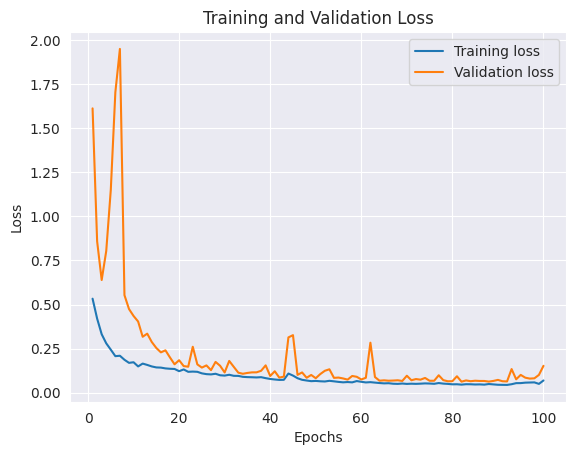

Pixel Accuracy: 0.9929839078403307
Dice Coefficient: 0.7260117780486769
Jaccard Index (IoU): 0.5698732260936213


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import json

MODEL_CHECKPOINT = f"/kaggle/working/model/{model_1.name}.ckpt"
EPOCHS = 100

callbacks_list = [
    keras.callbacks.EarlyStopping(monitor='val_dsc', mode='max', patience=10),
    keras.callbacks.ModelCheckpoint(filepath=MODEL_CHECKPOINT, monitor='val_dsc', save_best_only=True, mode='max', verbose=0)
]

history_1 = model_1.fit(
    x=X_train,
    y=y_train,
    epochs=EPOCHS,
    batch_size = bs,
    callbacks=callbacks_list,
    validation_split=0.2,
    verbose=1)


model_1.save("unet6.keras")
with open('history6.json', 'w') as f:
    json.dump(history_1.history, f)


y_pred = model_1.predict(X_test)
y_pred = (y_pred > 0.5).astype(np.float64)

def calculate_metrics(history):

  dice_scores = history.history['dice_coefficient']
  jaccard_scores = history.history['jaccard_index']
  pixel_accuracies = history.history['pixel_accuracy']
  sensitivity_scores = history.history['sensitivity']
  specificity_scores = history.history['specificity']
  accuracy_scores = history.history['accuracy']

  print("Final Dice Coefficient:", dice_scores[-1])
  print("Final Jaccard Index:", jaccard_scores[-1])
  print("Final Pixel Accuracy:", pixel_accuracies[-1])
  print("Final Sensitivity:", sensitivity_scores[-1])
  print("Final Specificity:", specificity_scores[-1])
  print("Final Accuracy:", accuracy_scores[-1])

  #calculate the average or maximum if needed
  print("Average Dice Coefficient:", sum(dice_scores) / len(dice_scores))

calculate_metrics(history_1)

import matplotlib.pyplot as plt

# Assuming 'history' contains the training history with loss values
train_loss = history_1.history['loss']
val_loss = history_1.history['val_loss']
epochs = range(1, len(train_loss) + 1)

plt.plot(epochs, train_loss, label='Training loss')
plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


calculate_metrics_sk_learn()

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix, accuracy_score

def calculate_metrics_sklearn(model1,y_pred_2):
  y_pred_2 = model1.predict(X_test)
  y_pred_2 = (y_pred_2 > 0.5).astype(np.float64)

  # Computing the confusion matrix
  cm = confusion_matrix(y_test.flatten(), y_pred_2.flatten())

  TP = cm[1, 1]
  FN = cm[1, 0]
  TN = cm[0, 0]
  FP = cm[0, 1]

  sensitivity = TP / (TP + FN)
  specificity = TN / (TN + FP)

  pixel_accuracy_1 = accuracy_score(y_test.flatten(), y_pred_2.flatten())
  dice_coefficient_1 = 2 * tf.reduce_sum(y_test * y_pred_2) / (tf.reduce_sum(y_test) + tf.reduce_sum(y_pred_2))
  intersection = np.logical_and(y_test, y_pred_2)
  union = np.logical_or(y_test, y_pred_2)
  iou_1 = np.sum(intersection) / np.sum(union)

  # Output results
  print("Confusion Matrix:")
  print(cm)
  print("Pixel Accuracy:", pixel_accuracy_1)
  print("Dice Coefficient:", dice_coefficient_1.numpy())
  print("Jaccard Index (IoU):", iou_1)
  print("Sensitivity (Recall):", sensitivity)
  print("Specificity:", specificity)

calculate_metrics_sklearn(model_1,y_pred)

25/25 [==============================] - 4s 145ms/step
Confusion Matrix:
[[12667765    82773]
 [    7579   119707]]
Pixel Accuracy: 0.9929839078403307
Dice Coefficient: 0.7260117780486769
Jaccard Index (IoU): 0.5698732260936213
Sensitivity (Recall): 0.9404569237779489
Specificity: 0.9935082739253825


## Tuning Learning rate

In [ ]:
from keras.optimizers import Adam

learning_rate = 0.0001
opt = Adam(lr=learning_rate)

bs = 32

model_1.compile(
    optimizer= opt,
    loss='binary_crossentropy',
    metrics=[
        dice_coefficient,
        jaccard_index,
        pixel_accuracy,
        sensitivity,
        specificity,
        'accuracy'
    ]
)
model_1.summary()

Model: "AttentionUnet"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 img (InputLayer)            [(None, 128, 128, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 128, 128, 64)         1792      ['img[0][0]']                 
                                                                                                  
 conv2d_1 (Conv2D)           (None, 128, 128, 64)         36928     ['conv2d[0][0]']              
                                                                                                  
 batch_normalization (Batch  (None, 128, 128, 64)         256       ['conv2d_1[0][0]']            
 Normalization)                                                                       

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import json

MODEL_CHECKPOINT = f"/kaggle/working/model/{model_1.name}.ckpt"
EPOCHS = 100

callbacks_list = [
    keras.callbacks.EarlyStopping(monitor='val_dsc', mode='max', patience=10),
    keras.callbacks.ModelCheckpoint(filepath=MODEL_CHECKPOINT, monitor='val_dsc', save_best_only=True, mode='max', verbose=0)
]

history_1 = model_1.fit(
    x=X_train,
    y=y_train,
    epochs=EPOCHS,
    batch_size = bs,
    callbacks=callbacks_list,
    validation_split=0.2,
    verbose=1)


model_1.save("unet11.keras")
with open('history11.json', 'w') as f:
    json.dump(history_1.history, f)

Epoch 1/100
63/63 [==============================] - ETA: 0s - loss: 0.0037 - dice_coefficient: 0.8945 - jaccard_index: 0.8098 - pixel_accuracy: 0.9985 - sensitivity: 0.9273 - specificity: 0.9993 - accuracy: 0.9985

63/63 [==============================] - 56s 659ms/step - loss: 0.0037 - dice_coefficient: 0.8945 - jaccard_index: 0.8098 - pixel_accuracy: 0.9985 - sensitivity: 0.9273 - specificity: 0.9993 - accuracy: 0.9985 - val_loss: 0.0066 - val_dice_coefficient: 0.8574 - val_jaccard_index: 0.7515 - val_pixel_accuracy: 0.9976 - val_sensitivity: 0.9004 - val_specificity: 0.9987 - val_accuracy: 0.9977
Epoch 2/100
63/63 [==============================] - ETA: 0s - loss: 0.0033 - dice_coefficient: 0.9053 - jaccard_index: 0.8275 - pixel_accuracy: 0.9987 - sensitivity: 0.9353 - specificity: 0.9994 - accuracy: 0.9987

63/63 [==============================] - 39s 613ms/step - loss: 0.0033 - dice_coefficient: 0.9053 - jaccard_index: 0.8275 - pixel_accuracy: 0.9987 - sensitivity: 0.9353 - specificity: 0.9994 - accuracy: 0.9987 - val_loss: 0.0072 - val_dice_coefficient: 0.8615 - val_jaccard_index: 0.7576 - val_pixel_accuracy: 0.9977 - val_sensitivity: 0.8524 - val_specificity: 0.9993 - val_accuracy: 0.9977
Epoch 3/100
63/63 [==============================] - ETA: 0s - loss: 0.0033 - dice_coefficient: 0.9049 - jaccard_index: 0.8268 - pixel_accuracy: 0.9986 - sensitivity: 0.9336 - specificity: 0.9993 - accuracy: 0.9986

63/63 [==============================] - 39s 623ms/step - loss: 0.0033 - dice_coefficient: 0.9049 - jaccard_index: 0.8268 - pixel_accuracy: 0.9986 - sensitivity: 0.9336 - specificity: 0.9993 - accuracy: 0.9986 - val_loss: 0.0070 - val_dice_coefficient: 0.8357 - val_jaccard_index: 0.7190 - val_pixel_accuracy: 0.9974 - val_sensitivity: 0.8659 - val_specificity: 0.9988 - val_accuracy: 0.9974
Epoch 4/100
63/63 [==============================] - ETA: 0s - loss: 0.0041 - dice_coefficient: 0.8861 - jaccard_index: 0.7965 - pixel_accuracy: 0.9984 - sensitivity: 0.9195 - specificity: 0.9992 - accuracy: 0.9984

63/63 [==============================] - 39s 619ms/step - loss: 0.0041 - dice_coefficient: 0.8861 - jaccard_index: 0.7965 - pixel_accuracy: 0.9984 - sensitivity: 0.9195 - specificity: 0.9992 - accuracy: 0.9984 - val_loss: 0.0161 - val_dice_coefficient: 0.7283 - val_jaccard_index: 0.5758 - val_pixel_accuracy: 0.9943 - val_sensitivity: 0.9272 - val_specificity: 0.9950 - val_accuracy: 0.9943
Epoch 5/100
63/63 [==============================] - ETA: 0s - loss: 0.0043 - dice_coefficient: 0.8787 - jaccard_index: 0.7854 - pixel_accuracy: 0.9983 - sensitivity: 0.9141 - specificity: 0.9992 - accuracy: 0.9983

...

63/63 [==============================] - 39s 619ms/step - loss: 5.7765e-04 - dice_coefficient: 0.9831 - jaccard_index: 0.9667 - pixel_accuracy: 0.9998 - sensitivity: 0.9890 - specificity: 0.9999 - accuracy: 0.9998 - val_loss: 0.0101 - val_dice_coefficient: 0.9009 - val_jaccard_index: 0.8201 - val_pixel_accuracy: 0.9981 - val_sensitivity: 0.8978 - val_specificity: 0.9991 - val_accuracy: 0.9981
Epoch 97/100
63/63 [==============================] - ETA: 0s - loss: 5.5671e-04 - dice_coefficient: 0.9839 - jaccard_index: 0.9683 - pixel_accuracy: 0.9998 - sensitivity: 0.9896 - specificity: 0.9999 - accuracy: 0.9998

63/63 [==============================] - 39s 619ms/step - loss: 5.5671e-04 - dice_coefficient: 0.9839 - jaccard_index: 0.9683 - pixel_accuracy: 0.9998 - sensitivity: 0.9896 - specificity: 0.9999 - accuracy: 0.9998 - val_loss: 0.0109 - val_dice_coefficient: 0.9021 - val_jaccard_index: 0.8221 - val_pixel_accuracy: 0.9981 - val_sensitivity: 0.9032 - val_specificity: 0.9991 - val_accuracy: 0.9981
Epoch 98/100
63/63 [==============================] - ETA: 0s - loss: 5.4881e-04 - dice_coefficient: 0.9842 - jaccard_index: 0.9689 - pixel_accuracy: 0.9998 - sensitivity: 0.9899 - specificity: 0.9999 - accuracy: 0.9998

63/63 [==============================] - 39s 618ms/step - loss: 5.4881e-04 - dice_coefficient: 0.9842 - jaccard_index: 0.9689 - pixel_accuracy: 0.9998 - sensitivity: 0.9899 - specificity: 0.9999 - accuracy: 0.9998 - val_loss: 0.0108 - val_dice_coefficient: 0.9016 - val_jaccard_index: 0.8213 - val_pixel_accuracy: 0.9981 - val_sensitivity: 0.8988 - val_specificity: 0.9991 - val_accuracy: 0.9981
Epoch 99/100
63/63 [==============================] - ETA: 0s - loss: 5.1893e-04 - dice_coefficient: 0.9851 - jaccard_index: 0.9707 - pixel_accuracy: 0.9998 - sensitivity: 0.9906 - specificity: 0.9999 - accuracy: 0.9998

63/63 [==============================] - 39s 618ms/step - loss: 5.1893e-04 - dice_coefficient: 0.9851 - jaccard_index: 0.9707 - pixel_accuracy: 0.9998 - sensitivity: 0.9906 - specificity: 0.9999 - accuracy: 0.9998 - val_loss: 0.0113 - val_dice_coefficient: 0.9011 - val_jaccard_index: 0.8205 - val_pixel_accuracy: 0.9981 - val_sensitivity: 0.8966 - val_specificity: 0.9991 - val_accuracy: 0.9981
Epoch 100/100
63/63 [==============================] - ETA: 0s - loss: 6.4221e-04 - dice_coefficient: 0.9821 - jaccard_index: 0.9650 - pixel_accuracy: 0.9997 - sensitivity: 0.9885 - specificity: 0.9999 - accuracy: 0.9997

63/63 [==============================] - 39s 620ms/step - loss: 6.4221e-04 - dice_coefficient: 0.9821 - jaccard_index: 0.9650 - pixel_accuracy: 0.9997 - sensitivity: 0.9885 - specificity: 0.9999 - accuracy: 0.9997 - val_loss: 0.0121 - val_dice_coefficient: 0.8917 - val_jaccard_index: 0.8052 - val_pixel_accuracy: 0.9979 - val_sensitivity: 0.8836 - val_specificity: 0.9991 - val_accuracy: 0.9979


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import load_model

import tensorflow as tf

import json

with open('history10.json', 'r') as f:
    history = json.load(f)

# @tf.keras.utils.register_keras_serializable()
# def dice_coefficient(y_true, y_pred, smooth=1e-6):
#     y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
#     y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
#     intersection = tf.reduce_sum(y_true_f * y_pred_f)
#     return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)


model = load_model('unet8.keras', custom_objects={
    'dice_coefficient': dice_coefficient,
    'jaccard_index':jaccard_index,
   ' pixel_accuracy':pixel_accuracy,
     'sensitivity': sensitivity,
       'specificity': specificity

})

OSError: Unable to open file (file signature not found)

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix, accuracy_score

y_pred_2 = model.predict(X_test)
y_pred_2 = (y_pred_2 > 0.5).astype(np.float64)

# Computing the confusion matrix
cm = confusion_matrix(y_test.flatten(), y_pred_2.flatten())

TP = cm[1, 1]
FN = cm[1, 0]
TN = cm[0, 0]
FP = cm[0, 1]

sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)

pixel_accuracy_1 = accuracy_score(y_test.flatten(), y_pred_2.flatten())
dice_coefficient_1 = 2 * tf.reduce_sum(y_test * y_pred_2) / (tf.reduce_sum(y_test) + tf.reduce_sum(y_pred_2))
intersection = np.logical_and(y_test, y_pred_2)
union = np.logical_or(y_test, y_pred_2)
iou_1 = np.sum(intersection) / np.sum(union)

# Output results
print("Confusion Matrix:")
print(cm)
print("Pixel Accuracy:", pixel_accuracy_1)
print("Dice Coefficient:", dice_coefficient_1.numpy())
print("Jaccard Index (IoU):", iou_1)
print("Sensitivity (Recall):", sensitivity)
print("Specificity:", specificity)

25/25 [==============================] - 19s 369ms/step
Confusion Matrix:
[[12735757     7405]
 [   11786   122876]]
Pixel Accuracy: 0.9985097637613312
Dice Coefficient: 0.9275655518356779
Jaccard Index (IoU): 0.8649158495639382
Sensitivity (Recall): 0.912477165050274
Specificity: 0.9994189040365334


In [ ]:

dice_scores = history_1.history['dice_coefficient']
jaccard_scores = history_1.history['jaccard_index']
pixel_accuracies = history_1.history['pixel_accuracy']
sensitivity_scores = history_1.history['sensitivity']
specificity_scores = history_1.history['specificity']
accuracy_scores = history_1.history['accuracy']

print("Final Dice Coefficient:", dice_scores[-1])
print("Final Jaccard Index:", jaccard_scores[-1])
print("Final Pixel Accuracy:", pixel_accuracies[-1])
print("Final Sensitivity:", sensitivity_scores[-1])
print("Final Specificity:", specificity_scores[-1])
print("Final Accuracy:", accuracy_scores[-1])

print("Average Dice Coefficient:", sum(dice_scores) / len(dice_scores))


Final Dice Coefficient: 0.9821435809135437
Final Jaccard Index: 0.9649659395217896
Final Pixel Accuracy: 0.9997495412826538
Final Sensitivity: 0.9885096549987793
Final Specificity: 0.9998720288276672
Final Accuracy: 0.9997497797012329
Average Dice Coefficient: 0.9489829981327057


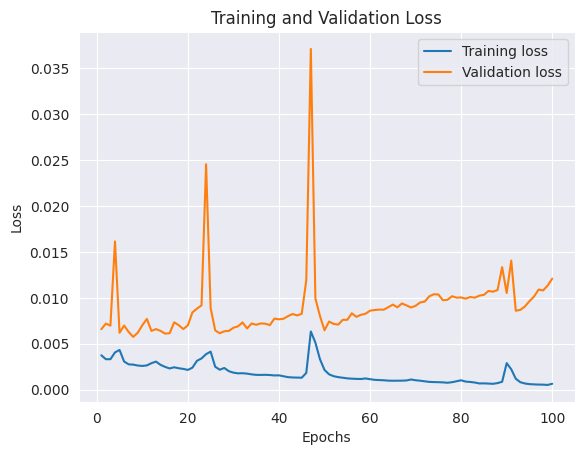

In [ ]:
import matplotlib.pyplot as plt

# Assuming 'history' contains the training history with loss values
train_loss = history_1.history['loss']
val_loss = history_1.history['val_loss']
epochs = range(1, len(train_loss) + 1)

plt.plot(epochs, train_loss, label='Training loss')
plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

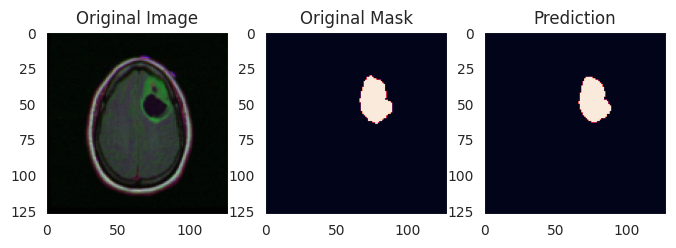

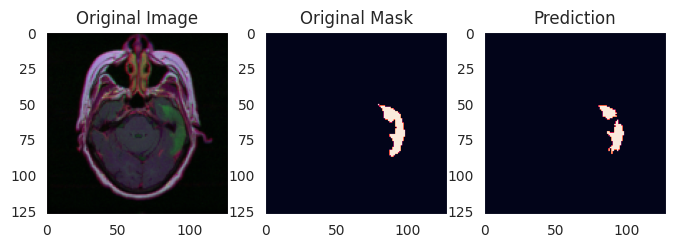

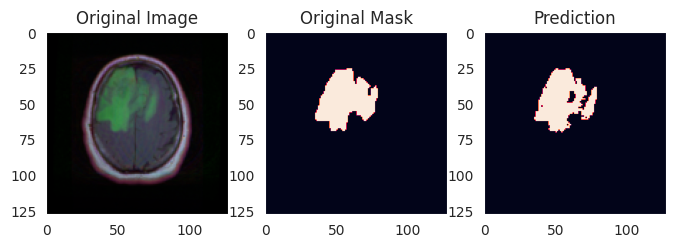

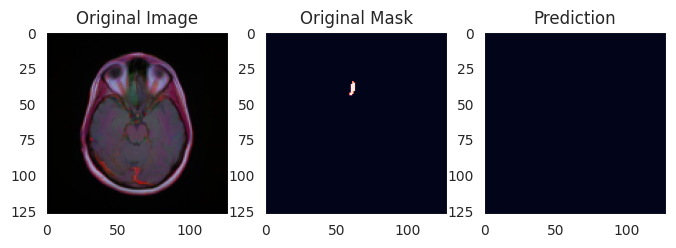

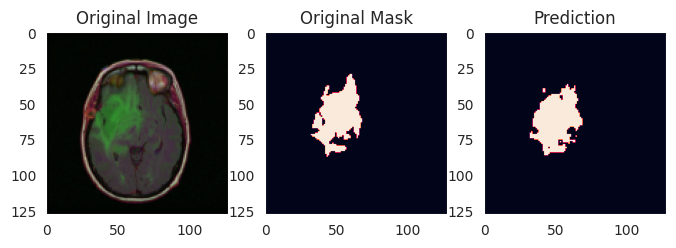

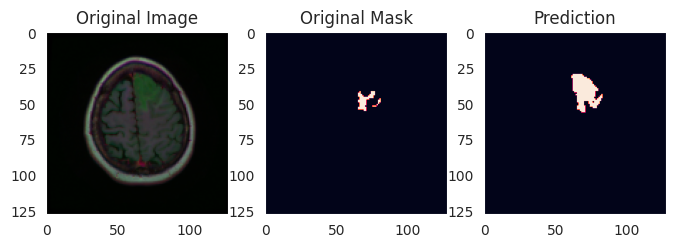

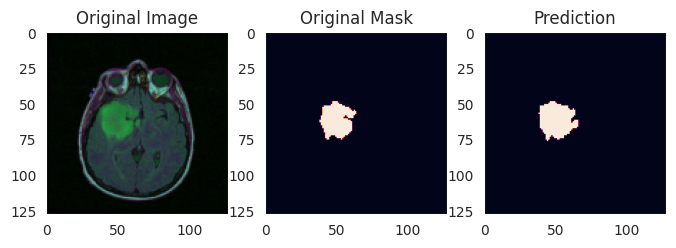

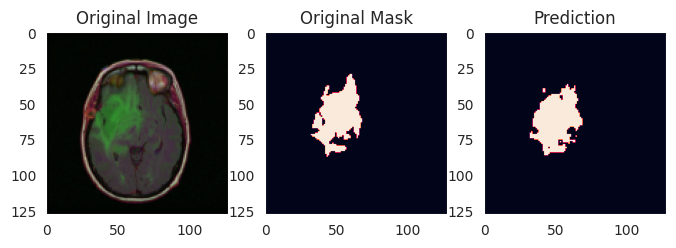

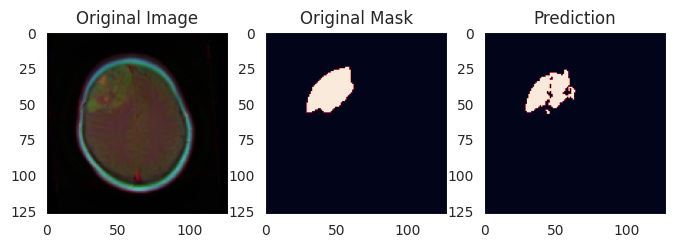

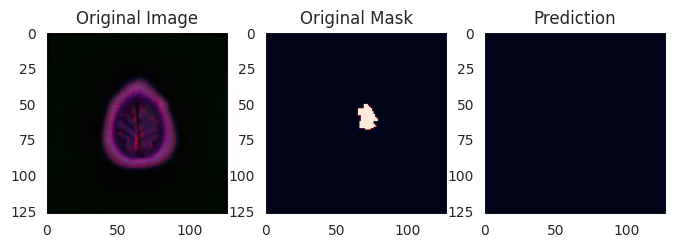

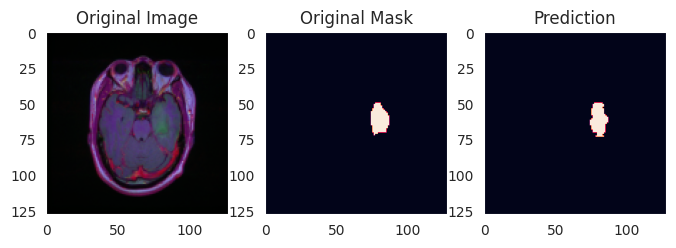

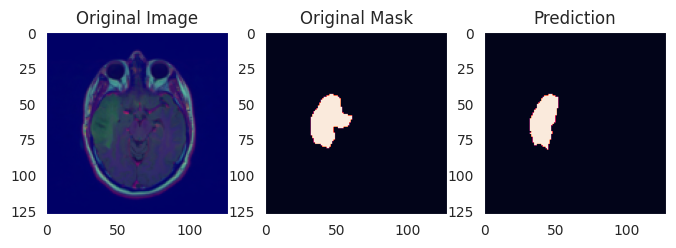

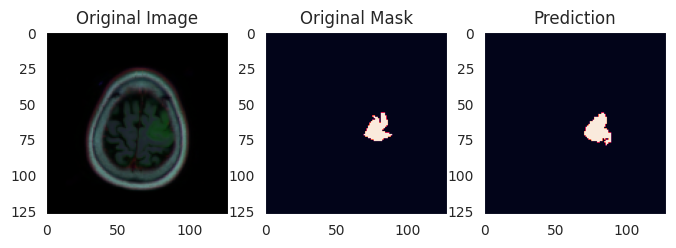

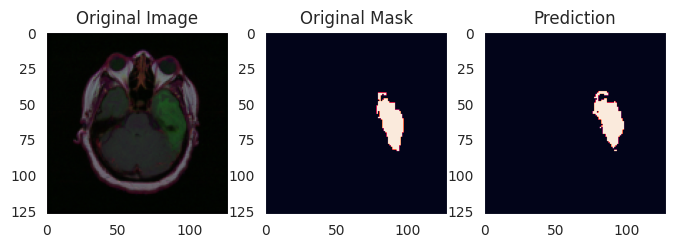

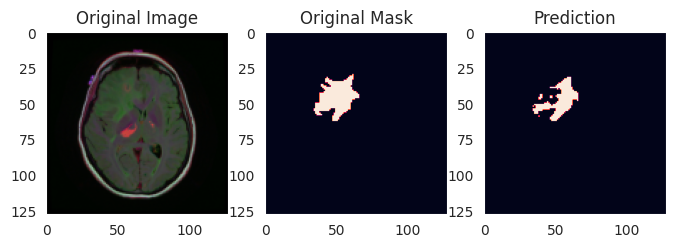

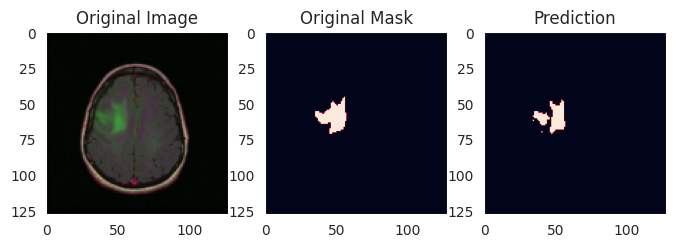

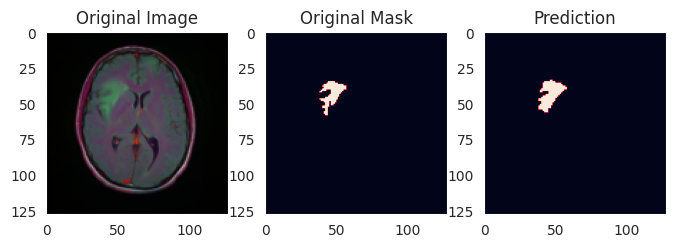

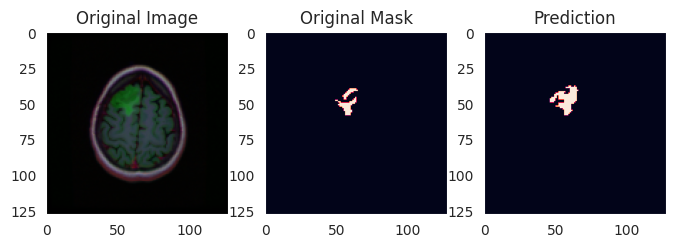

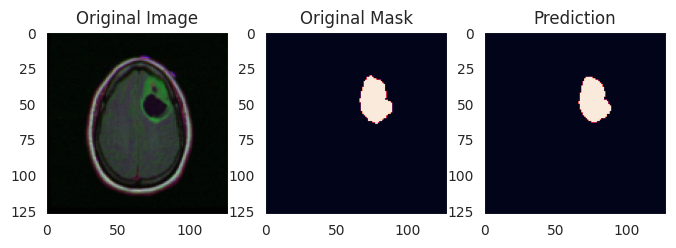

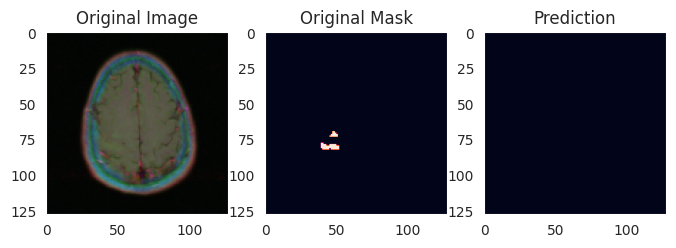

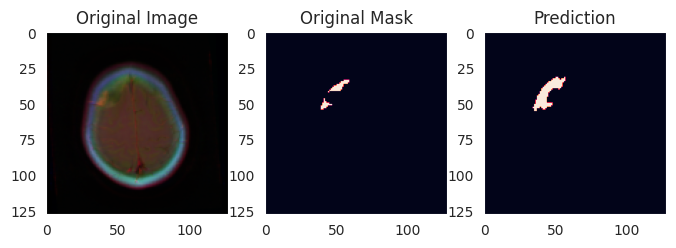

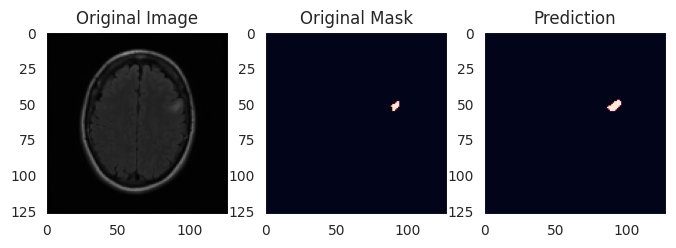

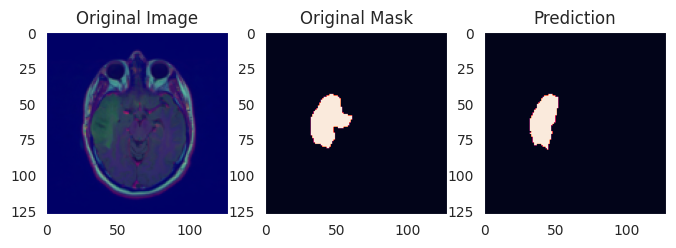

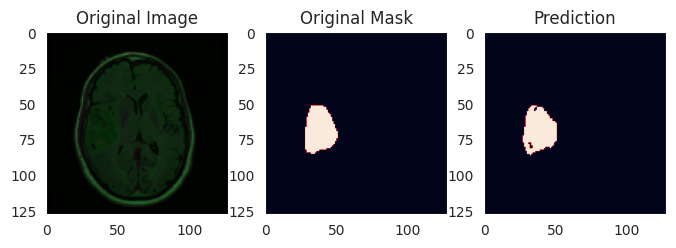

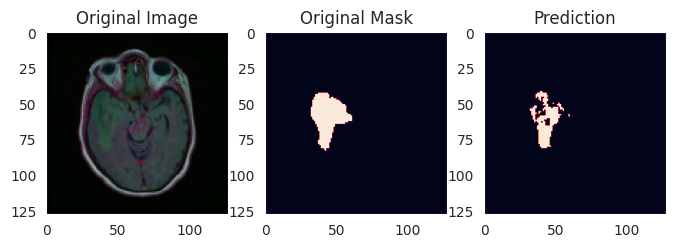

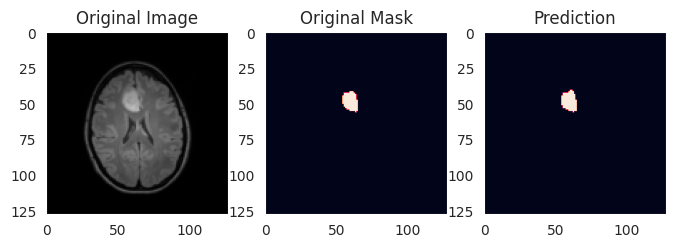

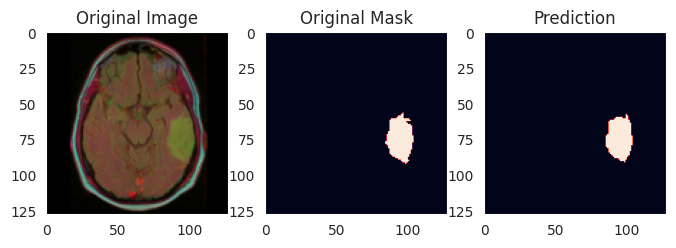

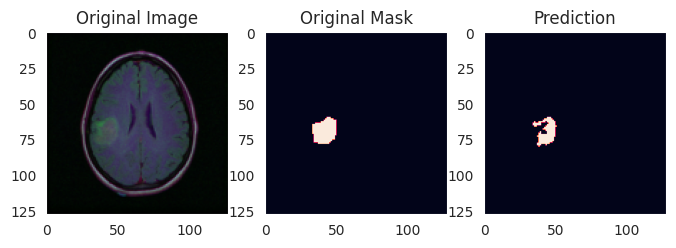

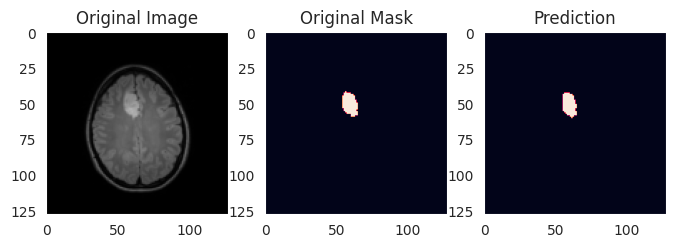

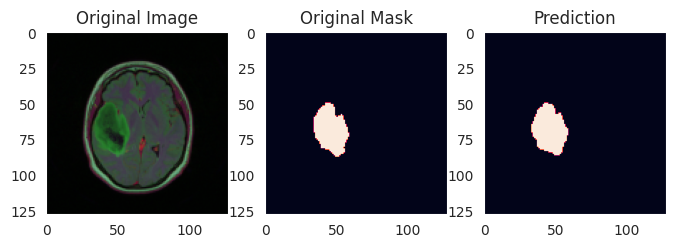

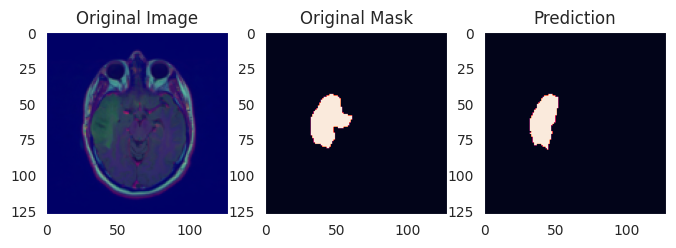

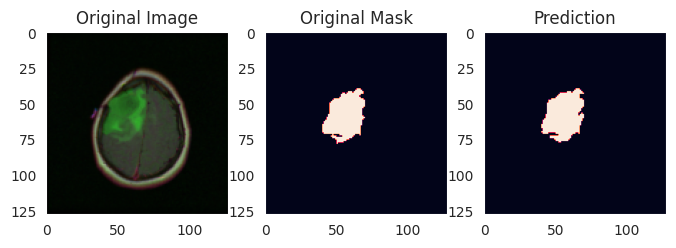

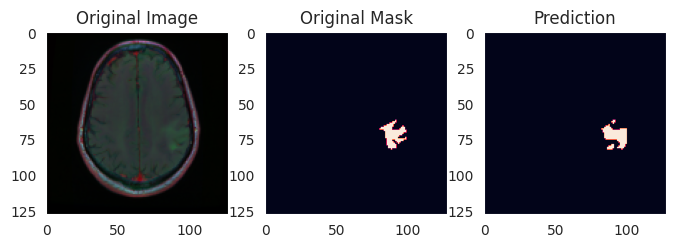

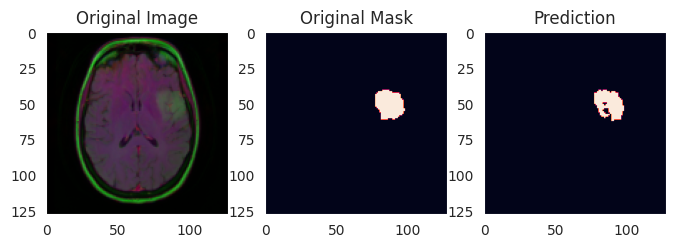

In [ ]:
for _ in range(100):
    i = np.random.randint(len(y_test))
    if y_test[i].sum() > 0:
        plt.figure(figsize=(8, 8))
        plt.subplot(1,3,1)
        plt.grid(False)
        plt.imshow(X_test[i])
        plt.title('Original Image')

        plt.subplot(1,3,2)
        plt.grid(False)
        plt.imshow(y_test[i])
        plt.title('Original Mask')

        plt.subplot(1,3,3)
        plt.imshow(y_pred_4[i])
        plt.title('Prediction')
        plt.grid(False)

        plt.show()

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

MODEL_CHECKPOINT = f"/kaggle/working/model/{model_1.name}.ckpt"
EPOCHS = 50


# callbacks_list = [
#     keras.callbacks.EarlyStopping(monitor='val_loss', mode='max', patience=5),
#     keras.callbacks.ModelCheckpoint(filepath=MODEL_CHECKPOINT, monitor='val_pixel_accuracy', save_best_only=True, mode='max', verbose=1)
# ]


early_stopping = EarlyStopping(monitor='val_sensitivity', patience=10, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint(filepath=MODEL_CHECKPOINT, monitor='val_sensitivity', save_best_only=True, mode='max', verbose=1)
callbacks_list = [early_stopping, checkpoint_callback]

history_2 = model_1.fit(
    x=X_train,
    y=y_train,
    epochs=EPOCHS,
    batch_size = 64,
    callbacks=callbacks_list,
    validation_split=0.2,
    verbose=1)

Epoch 1/20
20/20 [==============================] - ETA: 0s - loss: 0.0041 - dice_coefficient: 0.8765 - jaccard_index: 0.7810 - pixel_accuracy: 0.9984 - sensitivity: 0.9146 - specificity: 0.9992 - accuracy: 0.9984
Epoch 1: val_sensitivity improved from -inf to 0.85141, saving model to /kaggle/working/model/AttentionUnet.ckpt
20/20 [==============================] - 71s 4s/step - loss: 0.0041 - dice_coefficient: 0.8765 - jaccard_index: 0.7810 - pixel_accuracy: 0.9984 - sensitivity: 0.9146 - specificity: 0.9992 - accuracy: 0.9984 - val_loss: 0.0082 - val_dice_coefficient: 0.8381 - val_jaccard_index: 0.7224 - val_pixel_accuracy: 0.9973 - val_sensitivity: 0.8514 - val_specificity: 0.9989 - val_accuracy: 0.9973
Epoch 2/20
20/20 [==============================] - ETA: 0s - loss: 0.0037 - dice_coefficient: 0.8891 - jaccard_index: 0.8009 - pixel_accuracy: 0.9985 - sensitivity: 0.9227 - specificity: 0.9993 - accuracy: 0.9985
Epoch 2: val_sensitivity did not improve from 0.85141
20/20 [=========

In [ ]:
y_pred_5 = model_1.predict(X_test)
y_pred_5 = (y_pred_5 > 0.5).astype(np.float64)

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from tensorflow.keras.metrics import MeanIoU

# cm = confusion_matrix(y_test, y_pred)
pixel_accuracy_1 = accuracy_score(y_test.flatten(), y_pred_5.flatten())
dice_coefficient_1 = 2 * tf.reduce_sum(y_test * y_pred_5) / (tf.reduce_sum(y_test) + tf.reduce_sum(y_pred_5))
intersection = np.logical_and(y_test, y_pred_5)
union = np.logical_or(y_test, y_pred_5)
iou_1 = np.sum(intersection) / np.sum(union)
# Print the confusion matrix
# print("Confusion Matrix:")
# print(cm)
print("Pixel Accuracy:", pixel_accuracy_1)
print("Dice Coefficient:", dice_coefficient_1.numpy())
print("Jaccard Index (IoU):", iou_1)

13/13 [==============================] - 1s 45ms/step
Pixel Accuracy: 0.9972268606870229
Dice Coefficient: 0.8621711745090774
Jaccard Index (IoU): 0.7577336372517095


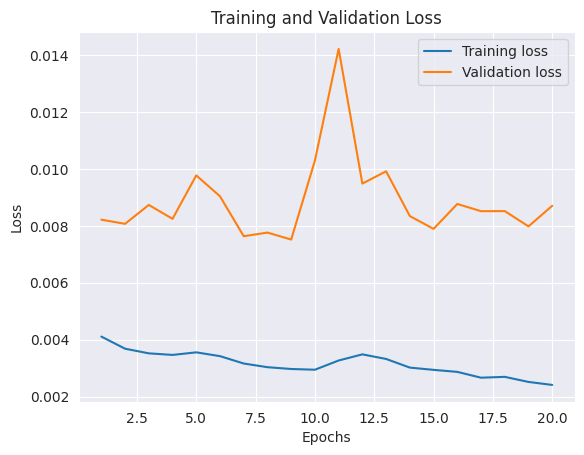

In [ ]:
import matplotlib.pyplot as plt

# Assuming 'history' contains the training history with loss values
train_loss = history_2.history['loss']
val_loss = history_2.history['val_loss']
epochs = range(1, len(train_loss) + 1)

plt.plot(epochs, train_loss, label='Training loss')
plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

MODEL_CHECKPOINT = f"/kaggle/working/model/{model_1.name}.ckpt"
EPOCHS = 50


# callbacks_list = [
#     keras.callbacks.EarlyStopping(monitor='val_loss', mode='max', patience=5),
#     keras.callbacks.ModelCheckpoint(filepath=MODEL_CHECKPOINT, monitor='val_pixel_accuracy', save_best_only=True, mode='max', verbose=1)
# ]


early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint(filepath=MODEL_CHECKPOINT, monitor='val_loss', save_best_only=True, mode='min', verbose=1)
callbacks_list = [early_stopping, checkpoint_callback]

history_3 = model_1.fit(
    x=X_train,
    y=y_train,
    epochs=EPOCHS,
    batch_size = 64,
    callbacks=callbacks_list,
    validation_split=0.2,
    verbose=1)

Epoch 1/50
20/20 [==============================] - ETA: 0s - loss: 0.0023 - dice_coefficient: 0.9295 - jaccard_index: 0.8684 - pixel_accuracy: 0.9990 - sensitivity: 0.9536 - specificity: 0.9995 - accuracy: 0.9990
Epoch 1: val_loss improved from inf to 0.00837, saving model to /kaggle/working/model/AttentionUnet.ckpt
20/20 [==============================] - 23s 1s/step - loss: 0.0023 - dice_coefficient: 0.9295 - jaccard_index: 0.8684 - pixel_accuracy: 0.9990 - sensitivity: 0.9536 - specificity: 0.9995 - accuracy: 0.9990 - val_loss: 0.0084 - val_dice_coefficient: 0.8583 - val_jaccard_index: 0.7527 - val_pixel_accuracy: 0.9975 - val_sensitivity: 0.8567 - val_specificity: 0.9990 - val_accuracy: 0.9975
Epoch 2/50
20/20 [==============================] - ETA: 0s - loss: 0.0021 - dice_coefficient: 0.9357 - jaccard_index: 0.8792 - pixel_accuracy: 0.9991 - sensitivity: 0.9536 - specificity: 0.9996 - accuracy: 0.9991
Epoch 2: val_loss did not improve from 0.00837
20/20 [========================